# 01 · Dataset Exploration

**Round 1 demo:** understand the input files, dataset partitions, trajectory quality, road network size, and geographical layout before choosing a model. This notebook analyzes the supplied data without modifying the raw files. The archive contains training and student-test trips; no evaluator-test partition was supplied.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
ROOT=Path.cwd()
if not (ROOT/"src").exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/"src"))
DATA=ROOT/"data"/"Student folder"
print("Project:",ROOT,"| dataset found:",DATA.exists())

Project: /Users/yashas/Documents/Codex/2026-11-18/referenced-chatgpt-conversation-this-is-an-2/ML_hackathon | dataset found: True


## Step 1 — Inventory the files and partitions

Every trip has four headerless files. `.track` is longitude, latitude, timestamp; `.nodes` is node longitude/latitude; `.arcs` connects node row IDs; `.route` lists reference arc row IDs in travel order. Arc and node IDs are local to each trip.

In [2]:
import pandas as pd, numpy as np
from pathsnap.eda import run
rows=run(DATA,ROOT/"outputs"/"dataset_inventory.csv")
inventory=pd.DataFrame(rows)
print("Trip counts by partition:")
display(inventory.groupby("partition").agg(trips=("trip_id","count"),gps_observations=("gps_rows","sum"),nodes=("node_rows","sum"),arcs=("arc_rows","sum"),route_entries=("route_rows","sum")))
print("Per-trip sizes (median, 10th, 90th percentile):")
display(inventory.groupby("partition")[["gps_rows","node_rows","arc_rows","route_rows"]].quantile([.1,.5,.9]).round(1))

Trip counts by partition:


,trips,gps_observations,nodes,arcs,route_entries
partition,,,,,
student_test,10,19160,90689,185041,3477
train,80,208417,1933485,3876904,31336


Per-trip sizes (median, 10th, 90th percentile):


gps_rows  node_rows  arc_rows  route_rows
partition                                                  
student_test 0.1     717.4     2031.9    4289.8       120.2
             0.5    1420.0     6596.5   13145.0       250.0
             0.9    3915.7    15946.6   30470.6       518.4
train        0.1     593.7     1879.1    3770.7       137.3
             0.5    1529.0     9608.0   19526.5       280.0
             0.9    4450.9    64962.8  129365.1       756.4

## Step 2 — Check data quality across trips

We examine finite coordinates, legal coordinate ranges, timestamp ordering, sampling intervals, and route-ID validity. Invalid timestamps are not sorted into a new order; cleaning preserves the vehicle’s observed sequence.

In [3]:
quality=inventory.groupby("partition").agg(
  raw_gps_rows=("raw_gps_rows","sum"),cleaned_gps_rows=("gps_rows","sum"),rows_removed=("preprocessing_rows_removed","sum"),
  nonincreasing_steps=("nonincreasing_timestamp_steps","sum"),one_second_steps=("one_second_steps","sum"),gaps_over_5s=("time_gap_over_5s_steps","sum"),
  route_rows=("route_rows","sum"),route_ids_in_arc_range=("route_arc_ids_in_range","sum"))
display(quality)
print("Route IDs valid in each trip:", bool((inventory.route_rows==inventory.route_arc_ids_in_range).all()))

,raw_gps_rows,cleaned_gps_rows,rows_removed,nonincreasing_steps,one_second_steps,gaps_over_5s,route_rows,route_ids_in_arc_range
partition,,,,,,,,
student_test,19160,19160,0,0,18886,44,3477,3477
train,208417,208417,0,0,201053,1216,31336,31336


Route IDs valid in each trip: True


## Step 3 — Inspect GPS sampling and trajectory scale

The dataset guide describes nominal 1 Hz sampling. We verify that from timestamp differences rather than assuming it. Large gaps remain visible because they affect speed and sequence decoding.

In [4]:
from pathsnap.data import read_trip
all_dt=[]
for part in ["train","student_test"]:
  for folder in sorted((DATA/part).iterdir()):
    if folder.is_dir() and (folder/f"{folder.name}.track").exists():
      t=read_trip(folder,part).track
      if len(t)>1: all_dt.extend(np.diff(t[:,2]).tolist())
dt=np.asarray(all_dt)
print({"timestamp_steps":len(dt),"fraction_exactly_1s":float(np.mean(np.isclose(dt,1))),"median_seconds":float(np.median(dt)),"p95_seconds":float(np.quantile(dt,.95)),"over_5s":int(np.sum(dt>5)),"nonpositive":int(np.sum(dt<=0))})

{'timestamp_steps': 227487, 'fraction_exactly_1s': 0.9668200820266653, 'median_seconds': 1.0, 'p95_seconds': 1.0, 'over_5s': 1260, 'nonpositive': 0}


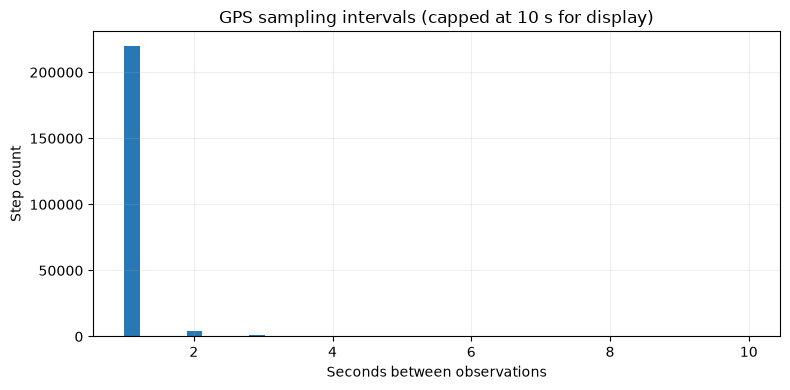

In [5]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(8,4)); ax.hist(dt[dt<=10],bins=40,color="#2878b5")
ax.set(title="GPS sampling intervals (capped at 10 s for display)",xlabel="Seconds between observations",ylabel="Step count"); ax.grid(alpha=.2); fig.tight_layout()

## Step 4 — Inspect a representative trajectory and its geography

The partitions contain trips in widely separated locations, so a single global coordinate plot can mislead. We inspect a trip locally and show its GPS observations, candidate roads, and reference route on an interactive map.

In [6]:
from pathsnap.matcher import generate_candidates
from pathsnap.visualize import create_map
from IPython.display import IFrame,display
trip=read_trip(DATA/"student_test"/"00000000","student_test")
batch=generate_candidates(trip,k=12)
nearest=batch.ids[np.arange(len(batch.ids)),batch.features[:,:,0].argmin(axis=1)]
map_path=ROOT/"maps"/"phase1_eda_map.html"
create_map(trip,batch,nearest,map_path)
print({"trip_id":trip.trip_id,"gps_points":len(trip.track),"network_nodes":len(trip.nodes),"network_arcs":len(trip.arcs),"reference_route_arcs":len(trip.route),"candidate_miss_rate":float(batch.candidate_miss.mean())})
display(IFrame(src=str(map_path),width="100%",height=500))

{'trip_id': '00000000', 'gps_points': 2503, 'network_nodes': 8542, 'network_arcs': 18196, 'reference_route_arcs': 179, 'candidate_miss_rate': 0.09788254095085897}


### What this exploration tells us

GPS points are sequential observations, while the nodes/arcs define a separate road graph. We must generate nearby road candidates and compare them with the supplied trip route; we cannot align raw GPS row numbers directly to node or arc row numbers. The candidate-miss rate is a limit on every classifier because an absent correct road cannot be selected.